# Paridad de riesgo: qué iguala realmente y qué pasa cuando cambia el régimen

**Perfil:** Gestión de portafolios  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

La paridad de riesgo promete repartir el **riesgo**, no el capital, de forma pareja. ¿Cuándo sí lo logra la regla simple de volatilidad inversa? ¿Qué cuesta ignorar los retornos esperados? ¿Cómo se comporta cuando la correlación acciones-bonos **cambia de signo**?

## Recorrido

1. Contribuciones al riesgo (descomposición de Euler) y el portafolio de contribuciones iguales (ERC).
2. **Versión 1:** volatilidad inversa. **Versión 2:** ERC exacto (formulación convexa de Spinu), comprobado contra un optimizador general.
3. **Diagnóstico:** cuándo coinciden; unicidad; volatilidad de ERC frente a mínima varianza y pesos iguales.
4. **Estimación:** estabilidad de pesos y error en las contribuciones con covarianza muestral.
5. **Cambio de régimen:** backtest con un régimen de estrés donde acciones y bonos caen juntos.
6. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf

## 2. Contribuciones al riesgo

Para pesos $w$ y covarianza $\Sigma$, el riesgo de la cartera es $\sigma_p=\sqrt{w^\top\Sigma w}$. Como $\sigma_p$ es **homogénea de grado 1** en $w$, el teorema de Euler da
$$\sigma_p=\sum_i w_i\frac{\partial\sigma_p}{\partial w_i}=\sum_i \underbrace{\frac{w_i(\Sigma w)_i}{\sigma_p}}_{\mathrm{RC}_i},$$
es decir, la **contribución al riesgo** del activo $i$ y la suma de contribuciones es exactamente el riesgo total. El portafolio de **paridad de riesgo** (ERC) busca $\mathrm{RC}_i=\sigma_p/n$ para todo $i$.

In [2]:
def contribuciones(w, S):
    sp = np.sqrt(w @ S @ w); return w * (S @ w) / sp, sp

# verificacion del teorema de Euler con una cartera arbitraria
rg = np.random.default_rng(0); A = rg.normal(size=(6, 6)); S_t = A @ A.T + 0.5 * np.eye(6); w_t = rg.dirichlet(np.ones(6))
rc_t, sp_t = contribuciones(w_t, S_t)
print(f"suma de contribuciones = {rc_t.sum():.10f} | riesgo total = {sp_t:.10f}")
assert abs(rc_t.sum() - sp_t) < 1e-12

suma de contribuciones = 1.1668006576 | riesgo total = 1.1668006576


## 3. El mundo verdadero: dos regímenes

Cinco activos con volatilidades y correlaciones realistas. Hay **dos regímenes** en cadena de Markov: **normal** (≈ 83 % del tiempo), con correlación acciones–bonos largos **negativa** (−0,2), y **estrés inflacionario** (≈ 17 %), con volatilidades más altas, correlación acciones–bonos **positiva** (+0,5) y retornos negativos tanto en acciones como en bonos (los bonos ya no cubren a las acciones).

In [3]:
ACT = ["acciones", "bonos_largos", "bonos_corp", "oro", "materias"]
N_A = len(ACT)
VOL_N = np.array([0.16, 0.09, 0.07, 0.15, 0.18])
C_N = np.array([[ 1.0, -0.20,  0.50,  0.00,  0.40],
                [-0.20,  1.0,  0.60,  0.20, -0.10],
                [ 0.50,  0.60,  1.0,  0.10,  0.20],
                [ 0.00,  0.20,  0.10,  1.0,  0.30],
                [ 0.40, -0.10,  0.20,  0.30,  1.0]])
VOL_S = VOL_N * np.array([1.8, 1.6, 1.4, 1.3, 1.6])
C_S = np.array([[ 1.0,  0.50,  0.70,  0.10,  0.50],
                [ 0.50,  1.0,  0.75,  0.25,  0.10],
                [ 0.70,  0.75,  1.0,  0.15,  0.30],
                [ 0.10,  0.25,  0.15,  1.0,  0.40],
                [ 0.50,  0.10,  0.30,  0.40,  1.0]])
for M in (C_N, C_S): assert np.all(np.linalg.eigvalsh(M) > 0)
S_N = np.outer(VOL_N, VOL_N) * C_N; S_S = np.outer(VOL_S, VOL_S) * C_S
MU_N = np.array([0.090, 0.045, 0.050, 0.040, 0.040]); MU_S = np.array([-0.15, -0.08, -0.06, 0.08, 0.10])
P_NS, P_SN = 0.03, 0.15; PI_S = P_NS / (P_NS + P_SN); PI_N = 1 - PI_S
MU_U = PI_N * MU_N + PI_S * MU_S
S_U = PI_N * (S_N + np.outer(MU_N, MU_N)) + PI_S * (S_S + np.outer(MU_S, MU_S)) - np.outer(MU_U, MU_U)
RF = 0.02
print(f"fraccion estacionaria en estres = {PI_S:.1%}")
print(pd.DataFrame({"vol normal": VOL_N, "vol estres": VOL_S, "mu normal": MU_N, "mu estres": MU_S, "vol incondicional": np.sqrt(np.diag(S_U))}, index=ACT).round(3).to_string())
print(f"correlacion acciones-bonos largos: normal {C_N[0, 1]:+.2f} | estres {C_S[0, 1]:+.2f} | incondicional {S_U[0, 1] / np.sqrt(S_U[0, 0] * S_U[1, 1]):+.2f}")

fraccion estacionaria en estres = 16.7%
              vol normal  vol estres  mu normal  mu estres  vol incondicional
acciones          0.1600      0.2880     0.0900    -0.1500             0.2080
bonos_largos      0.0900      0.1440     0.0450    -0.0800             0.1110
bonos_corp        0.0700      0.0980     0.0500    -0.0600             0.0860
oro               0.1500      0.1950     0.0400     0.0800             0.1590
materias          0.1800      0.2880     0.0400     0.1000             0.2030
correlacion acciones-bonos largos: normal -0.20 | estres +0.50 | incondicional +0.23


## 4. Versión 1: volatilidad inversa

La regla más simple: $w_i\propto 1/\sigma_i$. Iguala las contribuciones **si todas las correlaciones son iguales**; si no, no.

In [4]:
def vol_inversa(S): w = 1 / np.sqrt(np.diag(S)); return w / w.sum()

w_iv = vol_inversa(S_U)
rc_iv, sp_iv = contribuciones(w_iv, S_U)
pd.DataFrame({"peso": w_iv, "contribucion_al_riesgo_%": rc_iv / sp_iv * 100}, index=ACT).round(2)

,peso,contribucion_al_riesgo_%
acciones,0.1300,21.9200
bonos_largos,0.2500,20.0300
bonos_corp,0.3200,25.4900
oro,0.1700,15.1900
materias,0.1300,17.3800


In [5]:
print(f"Contribucion ideal: {100 / N_A:.1f}% por activo. Rango observado con volatilidad inversa: {rc_iv.min() / sp_iv * 100:.1f}% a {rc_iv.max() / sp_iv * 100:.1f}%.")
print(f"Razon entre la mayor y la menor contribucion: {rc_iv.max() / rc_iv.min():.1f}x")

Contribucion ideal: 20.0% por activo. Rango observado con volatilidad inversa: 15.2% a 25.5%.
Razon entre la mayor y la menor contribucion: 1.7x


## 5. Versión 2: ERC exacto

Las contribuciones iguales se obtienen minimizando una función **estrictamente convexa** (Spinu, 2013):
$$\min_{x>0}\ \tfrac12 x^\top\Sigma x-\tfrac1n\sum_i\ln x_i,\qquad w=x/\mathbf 1^\top x.$$
La condición de primer orden $(\Sigma x)_i=1/(n\,x_i)$ implica $x_i(\Sigma x)_i=1/n$: contribuciones iguales. Al ser estrictamente convexa, la solución es **única**. Se resuelve con Newton y se **compara con un optimizador general** (SLSQP) como verificación.

In [6]:
def erc(S, tol=1e-14, it=100):
    n = len(S); x = 1 / np.sqrt(np.diag(S)); b = 1.0 / n
    for _ in range(it):
        g = S @ x - b / x; J = S + np.diag(b / x ** 2)
        paso = np.linalg.solve(J, g); x_n = x - paso
        while (x_n <= 0).any(): paso *= 0.5; x_n = x - paso
        x = x_n
        if np.abs(g).max() < tol: break
    return x / x.sum()

def erc_slsqp(S, x0=None):
    n = len(S); obj = lambda w: ((contribuciones(np.abs(w) / np.abs(w).sum(), S)[0] - contribuciones(np.abs(w) / np.abs(w).sum(), S)[1] / n) ** 2).sum() * 1e4
    r = minimize(obj, np.full(n, 1 / n) if x0 is None else x0, method="SLSQP", bounds=[(1e-4, 1)] * n, options={"ftol": 1e-15, "maxiter": 1000})
    w = np.abs(r.x) / np.abs(r.x).sum(); return w

w_erc = erc(S_U); w_sl = erc_slsqp(S_U)
rc_e, sp_e = contribuciones(w_erc, S_U)
print("max |w_Spinu - w_SLSQP| =", np.abs(w_erc - w_sl).max().round(6))
pd.DataFrame({"vol_inversa": w_iv, "ERC": w_erc, "RC_ERC_%": rc_e / sp_e * 100, "RC_vol_inv_%": rc_iv / sp_iv * 100}, index=ACT).round(3)

max |w_Spinu - w_SLSQP| = 0.0


,vol_inversa,ERC,RC_ERC_%,RC_vol_inv_%
acciones,0.1310,0.1270,20.0000,21.9170
bonos_largos,0.2450,0.2560,20.0000,20.0310
bonos_corp,0.3180,0.2670,20.0000,25.4900
oro,0.1710,0.2020,20.0000,15.1860
materias,0.1340,0.1470,20.0000,17.3770


In [7]:
print("Lectura:")
print(f"  ERC: las contribuciones al riesgo van de {rc_e.min() / sp_e * 100:.4f}% a {rc_e.max() / sp_e * 100:.4f}% (ideal {100 / N_A:.1f}%). Volatilidad inversa: de {rc_iv.min() / sp_iv * 100:.1f}% a {rc_iv.max() / sp_iv * 100:.1f}%.")
dif = np.abs(w_erc - w_iv).sum() / 2
print(f"  La diferencia de pesos entre ERC y volatilidad inversa es {dif:.1%} (L1/2): ignorar las correlaciones cambia la cartera.")

Lectura:
  ERC: las contribuciones al riesgo van de 20.0000% a 20.0000% (ideal 20.0%). Volatilidad inversa: de 15.2% a 25.5%.
  La diferencia de pesos entre ERC y volatilidad inversa es 5.5% (L1/2): ignorar las correlaciones cambia la cartera.


### 5.1 Propiedades: cuándo coinciden, unicidad y ordenamiento de volatilidades

In [8]:
# (a) con correlacion IGUAL entre todos los pares, volatilidad inversa == ERC
vol_ = np.array([0.1, 0.15, 0.2, 0.3, 0.05]); rho_ = 0.35
S_eq = np.outer(vol_, vol_) * (rho_ + (1 - rho_) * np.eye(5))
dif_igual = np.abs(vol_inversa(S_eq) - erc(S_eq)).max()
# (b) con correlaciones distintas, no coinciden
dif_distinta = np.abs(vol_inversa(S_U) - erc(S_U)).max()
# (c) unicidad: Newton desde 30 puntos iniciales distintos converge al mismo portafolio; SLSQP desde otros inicios tambien
rg = np.random.default_rng(3)
def erc_desde(S, x0):
    n = len(S); x = x0.copy(); b = 1.0 / n
    for _ in range(200):
        g = S @ x - b / x; J = S + np.diag(b / x ** 2); paso = np.linalg.solve(J, g); xn = x - paso
        while (xn <= 0).any(): paso *= 0.5; xn = x - paso
        x = xn
        if np.abs(g).max() < 1e-13: break
    return x / x.sum()
dif_inicios = max(np.abs(erc_desde(S_U, rg.uniform(0.1, 20, N_A)) - w_erc).max() for _ in range(30))
# (d) orden de volatilidades (Maillard, Roncalli, Teiletche): vol(MV) <= vol(ERC) <= vol(EW)
def minvar(S):
    n = len(S); r = minimize(lambda w: w @ S @ w, np.full(n, 1 / n), bounds=[(0, 1)] * n, constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}], method="SLSQP", options={"ftol": 1e-14})
    return r.x
w_mv = minvar(S_U); w_ew = np.full(N_A, 1 / N_A)
vols = {"minima varianza": np.sqrt(w_mv @ S_U @ w_mv), "ERC": np.sqrt(w_erc @ S_U @ w_erc), "volatilidad inversa": np.sqrt(w_iv @ S_U @ w_iv), "pesos iguales": np.sqrt(w_ew @ S_U @ w_ew)}
print(f"(a) correlacion igual: max|w_vol_inv - w_ERC| = {dif_igual:.2e}  (deben coincidir)")
print(f"(b) correlaciones distintas: max|w_vol_inv - w_ERC| = {dif_distinta:.3f}")
print(f"(c) unicidad: desviacion maxima entre 30 inicios aleatorios = {dif_inicios:.2e}")
print("(d) volatilidades (incondicionales):", {k: round(float(v), 4) for k, v in vols.items()})

(a) correlacion igual: max|w_vol_inv - w_ERC| = 5.55e-17  (deben coincidir)
(b) correlaciones distintas: max|w_vol_inv - w_ERC| = 0.051
(c) unicidad: desviacion maxima entre 30 inicios aleatorios = 1.11e-16
(d) volatilidades (incondicionales): {'minima varianza': 0.0767, 'ERC': 0.0874, 'volatilidad inversa': 0.0866, 'pesos iguales': 0.0971}


### 5.2 El costo de ignorar los retornos esperados

ERC no usa las medias. Es Sharpe-óptimo solo si **todos los activos tienen el mismo Sharpe y las mismas correlaciones**. Aquí no es así. Se compara el **Sharpe verdadero** (con la media y covarianza incondicionales) de cada portafolio con el del portafolio tangente verdadero largo-solo.

In [9]:
def tangente(m, S, rf=RF):
    n = len(m); f = lambda w: -(w @ m - rf) / np.sqrt(w @ S @ w)
    r = minimize(f, np.full(n, 1 / n), bounds=[(0, 1)] * n, constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}], method="SLSQP", options={"ftol": 1e-14}); return r.x

sharpe_u = lambda w: (w @ MU_U - RF) / np.sqrt(w @ S_U @ w)
w_tg = tangente(MU_U, S_U); w_6040 = np.array([0.6, 0.4, 0, 0, 0.0])
comp = pd.DataFrame({"peso_acciones": [w[0] for w in (w_6040, w_ew, w_iv, w_erc, w_mv, w_tg)],
                     "retorno": [w @ MU_U for w in (w_6040, w_ew, w_iv, w_erc, w_mv, w_tg)],
                     "volatilidad": [np.sqrt(w @ S_U @ w) for w in (w_6040, w_ew, w_iv, w_erc, w_mv, w_tg)],
                     "Sharpe": [sharpe_u(w) for w in (w_6040, w_ew, w_iv, w_erc, w_mv, w_tg)]},
                    index=["60/40", "pesos iguales", "volatilidad inversa", "ERC", "minima varianza", "tangente (usa medias)"])
comp.round(4)

,peso_acciones,retorno,volatilidad,Sharpe
60/40,0.6000,0.0397,0.1415,0.1390
pesos iguales,0.2000,0.0405,0.0971,0.2112
volatilidad inversa,0.1313,0.0373,0.0866,0.1994
ERC,0.1274,0.0378,0.0874,0.2038
minima varianza,0.0000,0.0350,0.0767,0.1962
tangente (usa medias),0.1684,0.0428,0.0983,0.2325


In [10]:
print("Lectura:")
print(f"  Sharpe verdadero de ERC = {comp.loc['ERC', 'Sharpe']:.3f}; del tangente (que conoce las medias) = {comp.loc['tangente (usa medias)', 'Sharpe']:.3f}: ignorar las medias cuesta {comp.loc['tangente (usa medias)', 'Sharpe'] - comp.loc['ERC', 'Sharpe']:.3f} de Sharpe en este mundo.")
print(f"  Pero el tangente solo es alcanzable si las medias se CONOCEN; el notebook de Markowitz mostro que estimadas pierden mucho. ERC {'supera' if comp.loc['ERC', 'Sharpe'] > comp.loc['60/40', 'Sharpe'] else 'no supera'} a 60/40 en Sharpe incondicional ({comp.loc['60/40', 'Sharpe']:.3f}).")
print(f"  El retorno de ERC ({comp.loc['ERC', 'retorno']:.1%}) es bajo porque su volatilidad ({comp.loc['ERC', 'volatilidad']:.1%}) es baja: para igualar el riesgo de 60/40 habria que apalancarla (ver la seccion 7).")

Lectura:
  Sharpe verdadero de ERC = 0.204; del tangente (que conoce las medias) = 0.232: ignorar las medias cuesta 0.029 de Sharpe en este mundo.
  Pero el tangente solo es alcanzable si las medias se CONOCEN; el notebook de Markowitz mostro que estimadas pierden mucho. ERC supera a 60/40 en Sharpe incondicional (0.139).
  El retorno de ERC (3.8%) es bajo porque su volatilidad (8.7%) es baja: para igualar el riesgo de 60/40 habria que apalancarla (ver la seccion 7).


## 6. Estimación: ¿qué tan estable es con una covarianza muestral?

Se estima $\hat\Sigma$ con $T$ meses (en el régimen mixto) y se calculan los pesos de ERC, volatilidad inversa y mínima varianza. Se mide (i) la **rotación** de pesos entre historias, (ii) cuánto se **alejan las contribuciones verdaderas** de la igualdad, y (iii) el efecto de Ledoit-Wolf.

In [11]:
def simular_regimen(T, seed, estado0=None):
    rg = np.random.default_rng(seed); est = np.zeros(T, int)
    est[0] = rg.random() < PI_S if estado0 is None else estado0
    for t in range(1, T): est[t] = rg.random() < (1 - P_SN if est[t - 1] else P_NS)
    R = np.zeros((T, N_A))
    for r, (m, S) in enumerate(((MU_N, S_N), (MU_S, S_S))):
        k = est == r
        if k.any(): R[k] = rg.multivariate_normal(m / 12, S / 12, k.sum())
    return R, est

def pesos_est(R, lw=False):
    S = (LedoitWolf().fit(R).covariance_ if lw else np.cov(R.T)) * 12
    return {"vol inversa": vol_inversa(S), "ERC": erc(S), "ERC (LW)": erc(S) if not lw else erc(S), "minima varianza": minvar(S)}

def desvio_rc(w):
    rc, sp = contribuciones(w, S_U); return np.abs(rc / sp - 1 / N_A).sum() / 2         # distancia (L1/2) a la igualdad, con la covarianza VERDADERA

filas = []
for T in (60, 120, 240, 600):
    W = {k: [] for k in ("vol inversa", "ERC", "ERC (LW)", "minima varianza")}
    for i in range(80):
        R, _ = simular_regimen(T, 5000 + 7 * i + T)
        for k, w in pesos_est(R).items():
            if k != "ERC (LW)": W[k].append(w)
        W["ERC (LW)"].append(erc(LedoitWolf().fit(R).covariance_ * 12))
    for k, ws in W.items():
        ws = np.array(ws); rot = np.mean([0.5 * np.abs(ws[a] - ws[b]).sum() for a in range(30) for b in range(a + 1, 30)])
        filas.append({"T": T, "metodo": k, "rotacion": rot, "desvio_RC_verdadero": np.mean([desvio_rc(w) for w in ws]), "vol_verdadera": np.mean([np.sqrt(w @ S_U @ w) for w in ws])})
est = pd.DataFrame(filas)
est.pivot(index="metodo", columns="T", values="rotacion").round(3)

T,60,120,240,600
metodo,,,,
ERC,0.0660,0.0560,0.0360,0.0230
ERC (LW),0.0550,0.0490,0.0340,0.0220
minima varianza,0.2420,0.1770,0.1140,0.0650
vol inversa,0.0420,0.0360,0.0200,0.0140


In [12]:
print("Desvio de las contribuciones VERDADERAS respecto de la igualdad (L1/2), por metodo y T:")
print(est.pivot(index="metodo", columns="T", values="desvio_RC_verdadero").round(3).to_string())
rot = est.pivot(index="metodo", columns="T", values="rotacion")
print("\nLectura:")
print(f"  Rotacion con T=120: minima varianza {rot.loc['minima varianza', 120]:.3f} | ERC {rot.loc['ERC', 120]:.3f} | volatilidad inversa {rot.loc['vol inversa', 120]:.3f}. ERC {'es mas estable' if rot.loc['ERC', 120] < rot.loc['minima varianza', 120] else 'NO es mas estable'} que la minima varianza.")
d = est.pivot(index="metodo", columns="T", values="desvio_RC_verdadero")
print(f"  Aun estimando la covarianza, las contribuciones verdaderas de ERC quedan a {d.loc['ERC', 120]:.3f} de la igualdad con T=120, frente a {d.loc['vol inversa', 120]:.3f} de la volatilidad inversa.")
print(f"  El error de estimacion deja una contribucion residual: 'ERC con covarianza estimada' no es exactamente paridad con la covarianza VERDADERA.")

Desvio de las contribuciones VERDADERAS respecto de la igualdad (L1/2), por metodo y T:
T                  60     120    240    600
metodo                                     
ERC             0.0980 0.0790 0.0700 0.0680
ERC (LW)        0.0840 0.0680 0.0650 0.0650
minima varianza 0.5400 0.5320 0.5670 0.5960
vol inversa     0.1210 0.1090 0.1090 0.1100

Lectura:
  Rotacion con T=120: minima varianza 0.177 | ERC 0.056 | volatilidad inversa 0.036. ERC es mas estable que la minima varianza.
  Aun estimando la covarianza, las contribuciones verdaderas de ERC quedan a 0.079 de la igualdad con T=120, frente a 0.109 de la volatilidad inversa.
  El error de estimacion deja una contribucion residual: 'ERC con covarianza estimada' no es exactamente paridad con la covarianza VERDADERA.


## 7. El régimen de estrés: backtest con ventana móvil

Se simulan 40 años (480 meses) con **cambios de régimen**. Cada año se reestiman los pesos con una ventana de 60 meses y se invierte el año siguiente. Se comparan: **60/40**, pesos iguales, volatilidad inversa, ERC, **ERC apalancada** (escalada al 10 % de volatilidad *ex-ante*, con costo de financiamiento $r_f+1\%$ sobre lo prestado) y mínima varianza.

In [13]:
def backtest(R, est_reg, ventana=60, paso=12, vol_obj=0.10):
    T = len(R); estr = {k: [] for k in ("60/40", "pesos iguales", "vol inversa", "ERC", "ERC apalancada", "minima varianza")}; ret = {k: np.zeros(T - ventana) for k in estr}
    for t0 in range(ventana, T, paso):
        S = np.cov(R[t0 - ventana:t0].T) * 12; fin = min(t0 + paso, T)
        w = {"60/40": np.array([0.6, 0.4, 0, 0, 0.0]), "pesos iguales": np.full(N_A, 1 / N_A), "vol inversa": vol_inversa(S), "ERC": erc(S), "minima varianza": minvar(S)}
        lev = vol_obj / np.sqrt(w["ERC"] @ S @ w["ERC"]); w["ERC apalancada"] = w["ERC"] * lev
        for k, wk in w.items():
            r = R[t0:fin] @ wk
            if k == "ERC apalancada": r = r - (wk.sum() - 1) * (RF + 0.01) / 12 + 0 * r        # costo de financiar lo prestado
            ret[k][t0 - ventana:fin - ventana] = r
    return ret

def metricas(r):
    anual = r.mean() * 12; vol = r.std(ddof=1) * np.sqrt(12); riq = np.cumprod(1 + r); dd = (riq / np.maximum.accumulate(riq) - 1).min()
    return {"retorno": anual, "vol": vol, "sharpe": (anual - RF) / vol, "max_drawdown": dd}

filas = []
for i in range(100):
    R, est_reg = simular_regimen(480, 9000 + i); ret = backtest(R, est_reg)
    estres = est_reg[60:] == 1
    for k, r in ret.items():
        m = metricas(r); m.update({"metodo": k, "ret_en_estres_mensual_%": r[estres].mean() * 100 if estres.any() else np.nan, "peor_mes_%": r.min() * 100}); filas.append(m)
bt = pd.DataFrame(filas)
resumen = bt.groupby("metodo").agg(retorno=("retorno", "mean"), vol=("vol", "mean"), sharpe=("sharpe", "mean"), mdd_medio=("max_drawdown", "mean"), mdd_peor=("max_drawdown", "min"), ret_estres_pct=("ret_en_estres_mensual_%", "mean"))
resumen.round(3)

,retorno,vol,sharpe,mdd_medio,mdd_peor,ret_estres_pct
metodo,,,,,,
60/40,0.0430,0.1250,0.1930,-0.4750,-0.9470,-0.8690
ERC,0.0410,0.0830,0.2530,-0.2770,-0.5440,-0.1880
ERC apalancada,0.0440,0.1070,0.2230,-0.3650,-0.6270,-0.3250
minima varianza,0.0360,0.0740,0.2210,-0.2530,-0.5060,-0.2860
pesos iguales,0.0450,0.0940,0.2660,-0.3050,-0.6120,-0.0860
vol inversa,0.0400,0.0810,0.2520,-0.2750,-0.5440,-0.2120


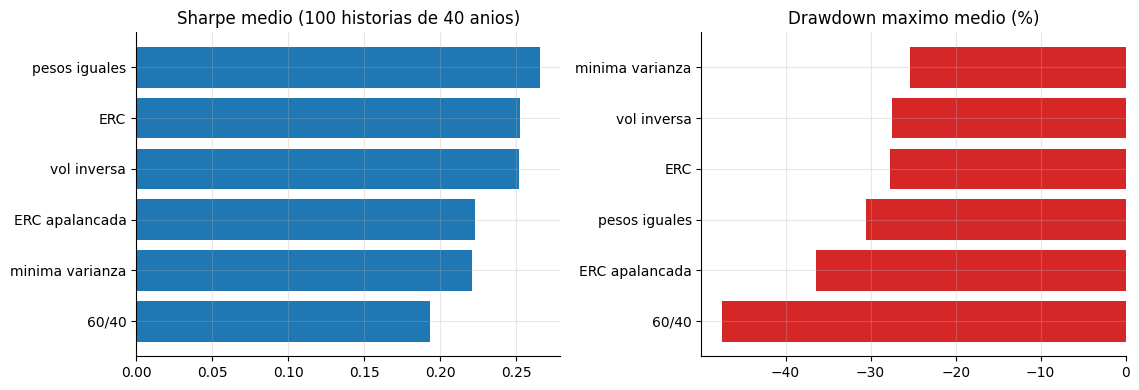

Lectura:
  60/40             : retorno 4.3% | vol 12.5% | Sharpe 0.19 | drawdown medio -48% (peor -95%) | retorno mensual en estres -0.87%
  ERC               : retorno 4.1% | vol 8.3% | Sharpe 0.25 | drawdown medio -28% (peor -54%) | retorno mensual en estres -0.19%
  ERC apalancada    : retorno 4.4% | vol 10.7% | Sharpe 0.22 | drawdown medio -36% (peor -63%) | retorno mensual en estres -0.33%
  minima varianza   : retorno 3.6% | vol 7.4% | Sharpe 0.22 | drawdown medio -25% (peor -51%) | retorno mensual en estres -0.29%
  pesos iguales     : retorno 4.5% | vol 9.4% | Sharpe 0.27 | drawdown medio -30% (peor -61%) | retorno mensual en estres -0.09%
  vol inversa       : retorno 4.0% | vol 8.1% | Sharpe 0.25 | drawdown medio -27% (peor -54%) | retorno mensual en estres -0.21%
  ERC frente a 60/40: Sharpe 0.25 vs 0.19; drawdown medio -28% vs -48%: la menor concentracion en acciones reduce el riesgo de cola.
  Pero los PESOS IGUALES tienen Sharpe 0.27 > ERC (0.25): la paridad de riesgo no 

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
ordenado = resumen.sort_values("sharpe"); ax[0].barh(ordenado.index, ordenado["sharpe"], color="C0"); ax[0].set_title("Sharpe medio (100 historias de 40 anios)")
ordenado2 = resumen.sort_values("mdd_medio"); ax[1].barh(ordenado2.index, ordenado2["mdd_medio"] * 100, color="C3"); ax[1].set_title("Drawdown maximo medio (%)")
plt.tight_layout(); plt.show()
print("Lectura:")
for m in resumen.index:
    f = resumen.loc[m]; print(f"  {m:18s}: retorno {f['retorno']:.1%} | vol {f['vol']:.1%} | Sharpe {f['sharpe']:.2f} | drawdown medio {f['mdd_medio']:.0%} (peor {f['mdd_peor']:.0%}) | retorno mensual en estres {f['ret_estres_pct']:+.2f}%")
e, p_, a_, ew, v6 = resumen.loc["ERC"], resumen.loc["60/40"], resumen.loc["ERC apalancada"], resumen.loc["pesos iguales"], resumen.loc["60/40"]
print(f"  ERC frente a 60/40: Sharpe {e['sharpe']:.2f} vs {p_['sharpe']:.2f}; drawdown medio {e['mdd_medio']:.0%} vs {p_['mdd_medio']:.0%}: la menor concentracion en acciones reduce el riesgo de cola.")
print(f"  Pero los PESOS IGUALES tienen Sharpe {ew['sharpe']:.2f} {'>' if ew['sharpe'] > e['sharpe'] else '<='} ERC ({e['sharpe']:.2f}): la paridad de riesgo no es superior por si misma a un 1/N en este mundo.")
print(f"  Apalancar ERC a ~10% de volatilidad {'BAJA' if a_['sharpe'] < e['sharpe'] else 'sube'} el Sharpe ({e['sharpe']:.2f} -> {a_['sharpe']:.2f}) por el costo de financiar lo prestado (rf + 1%): el apalancamiento solo ayuda si el costo de financiamiento es menor que el retorno marginal.")

### ¿Qué pasa en el régimen de estrés? Contribuciones **realizadas**

Las contribuciones de ERC son iguales con la covarianza **normal**, pero en estrés las correlaciones y volatilidades cambian. Se calcula, para los pesos de ERC estimados en régimen normal, cómo se reparte el riesgo **si el régimen pasa a estrés**.

In [15]:
w_n = erc(S_N); w_s = erc(S_S)
rc_n, sp_n = contribuciones(w_n, S_N); rc_ns, sp_ns = contribuciones(w_n, S_S)
tabla = pd.DataFrame({"peso ERC (normal)": w_n, "RC% con cov. normal": rc_n / sp_n * 100, "RC% si pasa a estres": rc_ns / sp_ns * 100, "peso ERC (estres)": w_s}, index=ACT)
print(f"Volatilidad del portafolio ERC(normal): {sp_n:.3f} en regimen normal -> {sp_ns:.3f} si pasa a estres ({sp_ns / sp_n - 1:+.0%}).")
tabla.round(2)

Volatilidad del portafolio ERC(normal): 0.069 en regimen normal -> 0.129 si pasa a estres (+88%).


,peso ERC (normal),RC% con cov. normal,RC% si pasa a estres,peso ERC (estres)
acciones,0.1600,20.0000,28.6100,0.1100
bonos_largos,0.3000,20.0000,24.8000,0.2400
bonos_corp,0.2500,20.0000,15.5500,0.3200
oro,0.1600,20.0000,12.5600,0.2100
materias,0.1300,20.0000,18.4900,0.1300


In [16]:
rc_acc_bonos_n = (rc_n[0] + rc_n[1]) / sp_n; rc_acc_bonos_s = (rc_ns[0] + rc_ns[1]) / sp_ns
print("Lectura:")
print(f"  Las contribuciones de ERC (calibradas en regimen normal) dejan de ser iguales: el rango pasa de {rc_n.min() / sp_n * 100:.0f}-{rc_n.max() / sp_n * 100:.0f}% a {rc_ns.min() / sp_ns * 100:.0f}-{rc_ns.max() / sp_ns * 100:.0f}%.")
print(f"  Acciones + bonos largos aportan {rc_acc_bonos_n:.0%} del riesgo en normal y {rc_acc_bonos_s:.0%} en estres: la cobertura natural entre acciones y bonos desaparece cuando su correlacion cambia de signo.")
print(f"  Paridad es una propiedad de UNA covarianza; con varios regimenes, 'iguales' deja de ser cierto fuera de aquel en que se calibro.")

Lectura:
  Las contribuciones de ERC (calibradas en regimen normal) dejan de ser iguales: el rango pasa de 20-20% a 13-29%.
  Acciones + bonos largos aportan 40% del riesgo en normal y 53% en estres: la cobertura natural entre acciones y bonos desaparece cuando su correlacion cambia de signo.
  Paridad es una propiedad de UNA covarianza; con varios regimenes, 'iguales' deja de ser cierto fuera de aquel en que se calibro.


## 8. Pruebas automáticas

In [17]:
# 8.1 Euler: la suma de contribuciones es el riesgo total y las contribuciones son aditivas
assert abs(rc_t.sum() - sp_t) < 1e-12
# 8.2 ERC: contribuciones iguales con precision numerica, pesos positivos que suman 1, y coincide con el optimizador general
assert np.abs(rc_e / sp_e - 1 / N_A).max() < 1e-9 and (w_erc > 0).all() and abs(w_erc.sum() - 1) < 1e-12
assert np.abs(w_erc - w_sl).max() < 2e-3
# 8.3 volatilidad inversa == ERC con correlacion igual, y distintas en general
assert dif_igual < 1e-9 and dif_distinta > 0.01
# 8.4 unicidad: de cualquier inicio positivo se llega al mismo portafolio
assert dif_inicios < 1e-8
# 8.5 orden de volatilidades de Maillard-Roncalli-Teiletche: MV <= ERC <= EW
assert vols["minima varianza"] <= vols["ERC"] + 1e-9 and vols["ERC"] <= vols["pesos iguales"] + 1e-9
# 8.6 la volatilidad inversa deja contribuciones desiguales y ERC no
assert (rc_iv.max() / rc_iv.min()) > 1.1 and (rc_e.max() / rc_e.min()) < 1 + 1e-6
# 8.7 ignorar las medias tiene un costo: el tangente verdadero tiene mayor Sharpe incondicional que ERC
assert comp.loc["tangente (usa medias)", "Sharpe"] > comp.loc["ERC", "Sharpe"]
# 8.8 estimacion: la rotacion baja con T; ERC es mas estable que la minima varianza
assert (rot.loc["ERC"].diff().dropna() < 0).all() and (rot.loc["minima varianza"].diff().dropna() < 0).all()
assert rot.loc["ERC", 120] < rot.loc["minima varianza", 120]
# 8.9 el desvio de las contribuciones verdaderas baja con T, y es menor con ERC que con volatilidad inversa
assert (d.loc["ERC"].diff().dropna() < 0).all() and d.loc["ERC", 120] < d.loc["vol inversa", 120]
# 8.10 el regimen de estres rompe la igualdad y la cobertura acciones-bonos
assert (rc_ns.max() / sp_ns - rc_ns.min() / sp_ns) > (rc_n.max() / sp_n - rc_n.min() / sp_n) + 0.05
assert sp_ns > sp_n and rc_acc_bonos_s > rc_acc_bonos_n
# 8.11b el backtest: ERC reduce drawdown y sube Sharpe frente a 60/40; los pesos iguales no son peores que ERC; apalancar con costo baja el Sharpe
assert resumen.loc["ERC", "mdd_medio"] > resumen.loc["60/40", "mdd_medio"] and resumen.loc["ERC", "sharpe"] > resumen.loc["60/40", "sharpe"]
assert resumen.loc["pesos iguales", "sharpe"] > resumen.loc["ERC", "sharpe"] - 0.03
assert resumen.loc["ERC apalancada", "sharpe"] < resumen.loc["ERC", "sharpe"]
# 8.11 backtest: los metricas son coherentes (apalancar sube el riesgo; el drawdown es no positivo)
assert resumen.loc["ERC apalancada", "vol"] > resumen.loc["ERC", "vol"] and (resumen["mdd_medio"] <= 0).all()
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Volatilidad inversa | Solo iguala las contribuciones al riesgo si todas las correlaciones son iguales | No presentarla como paridad de riesgo cuando las correlaciones difieren |
| ERC exacto | Existe y es único (problema convexo); las contribuciones salen iguales con precisión numérica | Resolver con la formulación convexa y verificar contra un optimizador general |
| Orden de volatilidades | vol(mínima varianza) ≤ vol(ERC) ≤ vol(pesos iguales) | ERC es un punto intermedio entre diversificación y concentración |
| Costo de ignorar medias | El tangente conocido tiene mayor Sharpe, pero solo es alcanzable con medias conocidas | Elegir según la confianza que se tenga en las medias |
| Backtest con regímenes | ERC reduce el drawdown medio (−28 % frente a −48 % de 60/40) y sube el Sharpe (0,25 frente a 0,19), pero los pesos iguales hacen igual o mejor (0,27); apalancar ERC con costo baja su Sharpe (0,25 → 0,22) | No presentar la paridad como superior a un 1/N; el apalancamiento tiene costo |
| Estimación | ERC es más estable que la mínima varianza, y sus contribuciones verdaderas quedan más cerca de la igualdad que con volatilidad inversa | Usar covarianzas contraídas y medir la rotación |
| Cambio de régimen | Las contribuciones dejan de ser iguales y la cobertura acciones-bonos se rompe cuando la correlación cambia de signo | Paridad es de UNA covarianza: probar bajo varios regímenes |

**Límites que no deben ocultarse**

- Hay solo dos regímenes en una cadena de Markov conocida; los regímenes reales son más variados y menos reconocibles en tiempo real.
- El portafolio apalancado supone un costo de financiamiento fijo de rf + 1 % y ninguna restricción de margen.
- No se incluyen costos de transacción ni impuestos (ver el notebook de backtest con costos).
- Los resultados del backtest dependen de la elección de ventana (60 meses) y de la frecuencia de rebalanceo (12 meses).
- Datos sintéticos: ningún valor numérico es extrapolable a una cartera real.